In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [3]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [4]:
observables = ['evid','xsec','pt','n','parton','nch','pt1','q1','eta1','phi1','pid1','parent1','pt2','q2','eta2','phi2','pid2','parent2',\
              'dr','m']

In [5]:
files = ['/gpfs/gibbs/project/havener/ys668/rc/pythia_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_50pthat1000_rc_truth.txt']

In [6]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [7]:
df = applyCut(df, 'pt>20')

In [8]:
np.unique(df['parton'])

array([-5, -4, -3, -2, -1,  0,  1,  2,  3,  4,  5, 21])

In [9]:
print(sum(df[(df.pt>20)&(df.pt<25)&(df.parton!=0)&(df.parton!=21)]['w'])/sum(df[(df.pt>20)&(df.pt<25)&(df.parton!=0)]['w']))
print(sum(df[(df.pt>40)&(df.pt<60)&(df.parton!=0)&(df.parton!=21)]['w'])/sum(df[(df.pt>40)&(df.pt<60)&(df.parton!=0)]['w']))

0.7262865707284978
0.8886722145342144


In [11]:
tot_prob = 0
for parton in np.unique(df['parton']):
    prob = sum(df[(df.pt>20)&(df.pt<25)&(df.parton==parton)]['w'])/sum(df[(df.pt>20)&(df.pt<25)]['w'])
    print('parton, prob:', parton, prob)
    tot_prob += prob
print(tot_prob)

parton, prob: -5 0.0015913244442553993
parton, prob: -4 0.016583275796576587
parton, prob: -3 0.005231601841053503
parton, prob: -2 0.021014090200561913
parton, prob: -1 0.026412991574299587
parton, prob: 0 0.10443276129065329
parton, prob: 1 0.17090310397115552
parton, prob: 2 0.38141285053300644
parton, prob: 3 0.004636505340897994
parton, prob: 4 0.02031037944644001
parton, prob: 5 0.002342335507869945
parton, prob: 21 0.24512878004996094
0.9999999999967312


In [14]:
for parton in np.unique(df['parton']):
    prob = sum(df[df.parton==parton]['w'])/sum(df['w'])
    print('parton, prob:', parton, prob)

parton, prob: -5 0.001558927125149174
parton, prob: -4 0.017781586608439332
parton, prob: -3 0.0048659748347895234
parton, prob: -2 0.019584710801793376
parton, prob: -1 0.025018336925373974
parton, prob: 0 0.09704848769445448
parton, prob: 1 0.17146042911402898
parton, prob: 2 0.39812989952601696
parton, prob: 3 0.004316227841913746
parton, prob: 4 0.022550018242948354
parton, prob: 5 0.0022574851231714024
parton, prob: 21 0.23542791621848413


In [55]:
parton_new = []
for i in range(0, df.shape[0]):
    parton = df.iloc[i]['parton']
    if (parton == 21):
        parton_new.append(6)
    else:
        parton_new.append(parton)

In [56]:
df['parton_new'] = parton_new

In [57]:
df.eval('b_ch = q1*q2', inplace=True)

In [58]:
df_array = []
for parton in np.unique(df['parton_new']):
    df_temp = df[df.parton_new==parton]
    df_array.append(df_temp)

In [59]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

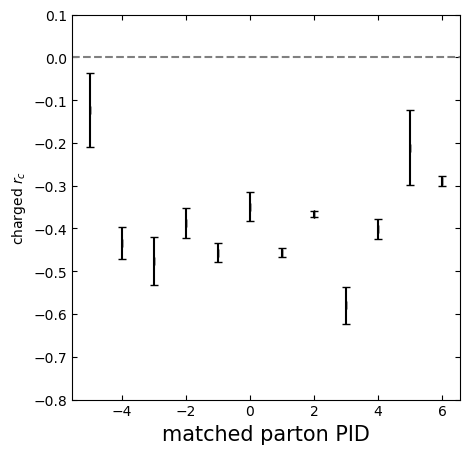

In [19]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(np.unique(df['parton_new']), rc_array, xerr=0, yerr=rc_err_array, capsize=3, ls='none', label='overall', color='k')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel('matched parton PID', fontsize=15)
plt.text(20,-0.125,'PYTHIA8 $p+p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.8,0.1)
#plt.legend(fontsize=12, loc='lower left', frameon=False)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

In [20]:
np.unique(df['w'])

array([3.567450e-05, 1.142115e-04, 4.724965e-04, 1.993005e-03,
       8.872100e-03, 4.341665e-02, 2.500510e-01, 1.898125e+00,
       1.278695e+01])

In [60]:
df = applyCut(df, '1e-2<w<1')
np.unique(df['w'])

array([0.04341665, 0.250051  ])

In [61]:
df_array = []
for parton in np.unique(df['parton_new']):
    df_temp = df[df.parton_new==parton]
    df_array.append(df_temp)

In [62]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

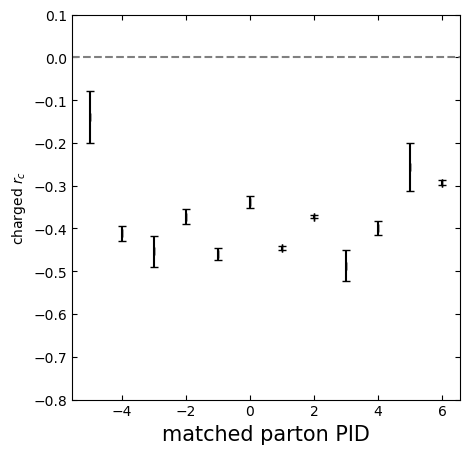

In [24]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(np.unique(df['parton_new']), rc_array, xerr=0, yerr=rc_err_array, capsize=3, ls='none', label='overall', color='k')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel('matched parton PID', fontsize=15)
#plt.text(20,-0.125,'PYTHIA8 $p+p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-0.8,0.1)
#plt.legend(fontsize=12, loc='lower left', frameon=False)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

In [72]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_20pthat25_nohad_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/pythia_25pthat30_nohad_rc_truth.txt']

In [73]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
    print(df.shape[0])
df_parton = pd.concat([df for df in df_array])

17564
24576


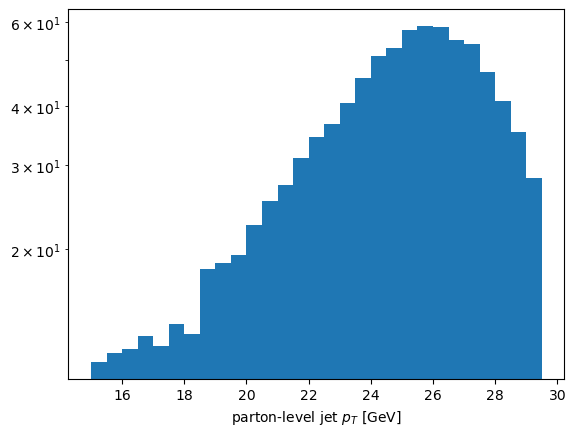

In [74]:
plt.hist(df['pt'], weights=df['w'], bins=np.arange(15,30,0.5))
plt.xlabel('parton-level jet $p_T$ [GeV]')
plt.yscale('log')

In [40]:
df_parton = applyCut(df_parton, 'pt>20')

In [41]:
np.unique(df_parton['parton'])

array([-5, -4, -3, -2, -1,  0,  1,  2,  3,  4,  5, 21])

In [43]:
parton_new = []
q1_new = []
q2_new = []
for i in range(0, df_parton.shape[0]):
    parton = df_parton.iloc[i]['parton']
    if (parton == 21):
        parton_new.append(6)
    else:
        parton_new.append(parton)
    q1 = df_parton.iloc[i]['q1']
    q2 = df_parton.iloc[i]['q2']
    if (q1 < 0):
        q1_new.append(-1)
    elif (q1 > 0):
        q1_new.append(1)
    if (q2 < 0):
        q2_new.append(-1)
    elif (q2 > 0):
        q2_new.append(1)

In [46]:
df_parton['parton_new'] = parton_new
df_parton['q1_new'] = q1_new
df_parton['q2_new'] = q2_new

In [47]:
df_parton.eval('b_ch = q1_new*q2_new', inplace=True)

In [48]:
df_parton_array = []
for parton in np.unique(df_parton['parton_new']):
    df_temp = df_parton[df_parton.parton_new==parton]
    df_parton_array.append(df_temp)

In [49]:
rc_parton_array = []
rc_parton_err_array = []
for i in range(0, len(df_parton_array)):
    rc_parton_array.append(getRcAndErr(df_parton_array[i], 'b_ch')[0])
    rc_parton_err_array.append(getRcAndErr(df_parton_array[i], 'b_ch')[1])

In [75]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(np.unique(df['parton_new']), rc_array, xerr=0, yerr=rc_err_array, capsize=3, ls='none', label='hadron-level jet', color='k')
plt.errorbar(np.unique(df_parton['parton_new']), rc_parton_array, xerr=0, yerr=rc_parton_err_array, capsize=3, ls='none', label='parton-level jet', color='b')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel('matched parton PID', fontsize=15)
plt.text(-5, -0.9, r'PYTHIA8 $p+p$ $\sqrt{s}=200$ GeV $20<\hat{p_T}<30$ GeV'+'\nanti-$k_\mathrm{T}$ jets $R=0.4$, $p_T>20$ GeV, $|\eta|<0.6$')
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
#plt.ylim(-0.8,0.1)
plt.legend(fontsize=12)#, loc='lower left', frameon=False)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

KeyError: 'parton_new'

<Figure size 500x500 with 0 Axes>